Import TensorFlow and verify its version and GPU availability for deep learning model training.

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!nvidia-smi

Sun Oct  4 13:00:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Mount the google drive to access the data,saved models and the project files

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/BrainTumor_BO_Reproduction"
DATASET_DIR = os.path.join(BASE_DIR, "dataset")

print("Project folder exists:", os.path.exists(BASE_DIR))
print("Dataset folder exists:", os.path.exists(DATASET_DIR))

print("\nProject folder contents:")
print(os.listdir(BASE_DIR))

print("\nDataset folder contents:")
print(os.listdir(DATASET_DIR))

Project folder exists: True
Dataset folder exists: True

Project folder contents:
['Reproduction_dataset1.ipynb', 'dataset']

Dataset folder contents:
['dataset1.zip', 'dataset2.zip']


In [ ]:
import zipfile
import os

zip_path = os.path.join(DATASET_DIR, "dataset1.zip")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    file_list = zip_ref.namelist()

print("Total items in ZIP:", len(file_list))
print("\nFirst 30 items:")
for item in file_list[:30]:
    print(item)

Total items in ZIP: 3264

First 30 items:
Testing/glioma_tumor/image(1).jpg
Testing/glioma_tumor/image(10).jpg
Testing/glioma_tumor/image(100).jpg
Testing/glioma_tumor/image(11).jpg
Testing/glioma_tumor/image(12).jpg
Testing/glioma_tumor/image(13).jpg
Testing/glioma_tumor/image(14).jpg
Testing/glioma_tumor/image(15).jpg
Testing/glioma_tumor/image(16).jpg
Testing/glioma_tumor/image(17).jpg
Testing/glioma_tumor/image(18).jpg
Testing/glioma_tumor/image(19).jpg
Testing/glioma_tumor/image(2).jpg
Testing/glioma_tumor/image(20).jpg
Testing/glioma_tumor/image(21).jpg
Testing/glioma_tumor/image(22).jpg
Testing/glioma_tumor/image(23).jpg
Testing/glioma_tumor/image(24).jpg
Testing/glioma_tumor/image(25).jpg
Testing/glioma_tumor/image(26).jpg
Testing/glioma_tumor/image(27).jpg
Testing/glioma_tumor/image(28).jpg
Testing/glioma_tumor/image(29).jpg
Testing/glioma_tumor/image(3).jpg
Testing/glioma_tumor/image(30).jpg
Testing/glioma_tumor/image(31).jpg
Testing/glioma_tumor/image(32).jpg
Testing/glioma_

In [ ]:
from collections import Counter

# Count files by top-level folder and class
counts = Counter()

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    for item in zip_ref.namelist():
        if item.lower().endswith(('.jpg', '.jpeg', '.png')):
            parts = item.split('/')

            if len(parts) >= 3:
                split = parts[0]
                class_name = parts[1]
                counts[(split, class_name)] += 1

print("Image counts:")
for (split, class_name), count in sorted(counts.items()):
    print(f"{split:10s} | {class_name:20s} | {count}")

Image counts:
Testing    | glioma_tumor         | 100
Testing    | meningioma_tumor     | 115
Testing    | no_tumor             | 105
Testing    | pituitary_tumor      | 74
Training   | glioma_tumor         | 826
Training   | meningioma_tumor     | 822
Training   | no_tumor             | 395
Training   | pituitary_tumor      | 827


In [ ]:
import os
import zipfile

EXTRACT_DIR = "/content/brain_tumor_dataset1"

# Extract only if it hasn't already been extracted
if not os.path.exists(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print("Folders:", os.listdir(EXTRACT_DIR))

Dataset extracted successfully!
Folders: ['Training', 'Testing']


Scanning the training and the testing folders and counting the images avaliable in the each class

In [ ]:
import os
import pandas as pd

image_data = []

for split in ["Training", "Testing"]:
    split_path = os.path.join(EXTRACT_DIR, split)

    for class_name in os.listdir(split_path):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            for filename in os.listdir(class_path):
                if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                    image_data.append({
                        "path": os.path.join(class_path, filename),
                        "class": class_name
                    })

df = pd.DataFrame(image_data)

print("Total images:", len(df))
print("\nImages per class:")
print(df["class"].value_counts())

Total images: 3264

Images per class:
class
meningioma_tumor    937
glioma_tumor        926
pituitary_tumor     901
no_tumor            500
Name: count, dtype: int64


Split the dataset into a fixed, class-balanced test set and the remaining data for training and validation.

In [ ]:
from sklearn.model_selection import train_test_split

test_counts = {
    "glioma_tumor": 185,
    "meningioma_tumor": 187,
    "no_tumor": 100,
    "pituitary_tumor": 180
}

test_parts = []
remaining_parts = []

for class_name, n_test in test_counts.items():
    class_df = df[df["class"] == class_name].copy()


    class_test = class_df.sample(n=n_test, random_state=42)
    class_remaining = class_df.drop(class_test.index)

    test_parts.append(class_test)
    remaining_parts.append(class_remaining)

test_df = pd.concat(test_parts).sample(frac=1, random_state=42).reset_index(drop=True)
remaining_df = pd.concat(remaining_parts).sample(frac=1, random_state=42).reset_index(drop=True)

print("Test images:", len(test_df))
print("\nTest class distribution:")
print(test_df["class"].value_counts())

print("\nRemaining images:", len(remaining_df))

Test images: 652

Test class distribution:
class
meningioma_tumor    187
glioma_tumor        185
pituitary_tumor     180
no_tumor            100
Name: count, dtype: int64

Remaining images: 2612



 Split the remaining data into training and validation sets while maintaining the same class distribution.



In [ ]:
train_df, val_df = train_test_split(
    remaining_df,
    test_size=261,
    stratify=remaining_df["class"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("\nTraining class distribution:")
print(train_df["class"].value_counts())

print("\nValidation images:", len(val_df))
print("\nValidation class distribution:")
print(val_df["class"].value_counts())

Training images: 2351

Training class distribution:
class
meningioma_tumor    675
glioma_tumor        667
pituitary_tumor     649
no_tumor            360
Name: count, dtype: int64

Validation images: 261

Validation class distribution:
class
meningioma_tumor    75
glioma_tumor        74
pituitary_tumor     72
no_tumor            40
Name: count, dtype: int64


Check the dimensions and color mode of sample training images to understand the dataset before preprocessing.


In [ ]:
from PIL import Image


sample_paths = train_df["path"].head(10)

print("Sample image dimensions:\n")

for path in sample_paths:
    with Image.open(path) as img:
        print(os.path.basename(path), "->", img.size, img.mode)

Sample image dimensions:

image(34).jpg -> (366, 395) RGB
p (338).jpg -> (512, 512) RGB
m3 (121).jpg -> (512, 512) RGB
m (87).jpg -> (512, 512) RGB
m1(27).jpg -> (512, 512) RGB
m3 (231).jpg -> (512, 512) RGB
m1(17).jpg -> (512, 512) RGB
m3 (97).jpg -> (512, 512) RGB
gg (491).jpg -> (512, 512) RGB
p (773).jpg -> (512, 512) RGB


Analyze the dataset to find and count the most common image dimensions.


In [ ]:
from collections import Counter
from PIL import Image

size_counts = Counter()

for path in df["path"]:
    try:
        with Image.open(path) as img:
            size_counts[img.size] += 1
    except Exception as e:
        print("Error reading:", path, e)

print("Number of unique image sizes:", len(size_counts))

print("\nMost common image sizes:")
for size, count in size_counts.most_common(15):
    print(f"{size}: {count} images")

Number of unique image sizes: 440

Most common image sizes:
(512, 512): 2341 images
(236, 236): 79 images
(225, 225): 43 images
(442, 442): 22 images
(256, 256): 18 images
(630, 630): 14 images
(201, 251): 10 images
(350, 350): 10 images
(236, 260): 8 images
(236, 251): 8 images
(554, 554): 7 images
(235, 227): 7 images
(236, 262): 6 images
(234, 218): 6 images
(455, 500): 5 images


Define the input image size and the four tumor classes for the CNN model.


In [ ]:
IMG_SIZE = (224, 224)
NUM_CLASSES = 4

CLASS_NAMES = [
    "glioma_tumor",
    "meningioma_tumor",
    "pituitary_tumor",
    "no_tumor"
]

print("Image size:", IMG_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASS_NAMES)

Image size: (224, 224)
Number of classes: 4
Classes: ['glioma_tumor', 'meningioma_tumor', 'pituitary_tumor', 'no_tumor']


In [ ]:
import tensorflow as tf
import math


# Settings

IMG_SIZE = (224, 224)
NUM_CLASSES = 4
BO_BATCH_SIZE = 8


# Class mapping

class_to_index = {
    "glioma_tumor": 0,
    "meningioma_tumor": 1,
    "pituitary_tumor": 2,
    "no_tumor": 3
}

# Convert dataframe labels to integers

train_paths = train_df["path"].values
train_labels = train_df["class"].map(class_to_index).values

val_paths = val_df["path"].values
val_labels = val_df["class"].map(class_to_index).values

test_paths = test_df["path"].values
test_labels = test_df["class"].map(class_to_index).values


# Image loading function

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    return image, label


# Create TRAIN dataset

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = (
    train_ds
    .shuffle(len(train_df), seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BO_BATCH_SIZE)
    .repeat()
    .prefetch(tf.data.AUTOTUNE)
)


# Create VALIDATION dataset

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = (
    val_ds
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BO_BATCH_SIZE)
    .repeat()
    .prefetch(tf.data.AUTOTUNE)
)



# Create TEST dataset

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = (
    test_ds
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BO_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# Steps

BO_TRAIN_STEPS = math.ceil(
    len(train_df) / BO_BATCH_SIZE
)

BO_VAL_STEPS = math.ceil(
    len(val_df) / BO_BATCH_SIZE
)

BO_TEST_STEPS = math.ceil(
    len(test_df) / BO_BATCH_SIZE
)



print("=" * 50)
print("DATASET SETUP COMPLETE")
print("=" * 50)

print("Training images :", len(train_df))
print("Validation images:", len(val_df))
print("Testing images   :", len(test_df))

print("Batch size       :", BO_BATCH_SIZE)
print("Image size       :", IMG_SIZE)

print("Training steps   :", BO_TRAIN_STEPS)
print("Validation steps :", BO_VAL_STEPS)
print("Testing steps    :", BO_TEST_STEPS)

DATASET SETUP COMPLETE
Training images : 2351
Validation images: 261
Testing images   : 652
Batch size       : 8
Image size       : (224, 224)
Training steps   : 294
Validation steps : 33
Testing steps    : 82


Image batch shape: (8, 224, 224, 3)
Label batch shape: (8,)
First labels: [2 0 0 2 3 1 0 2]


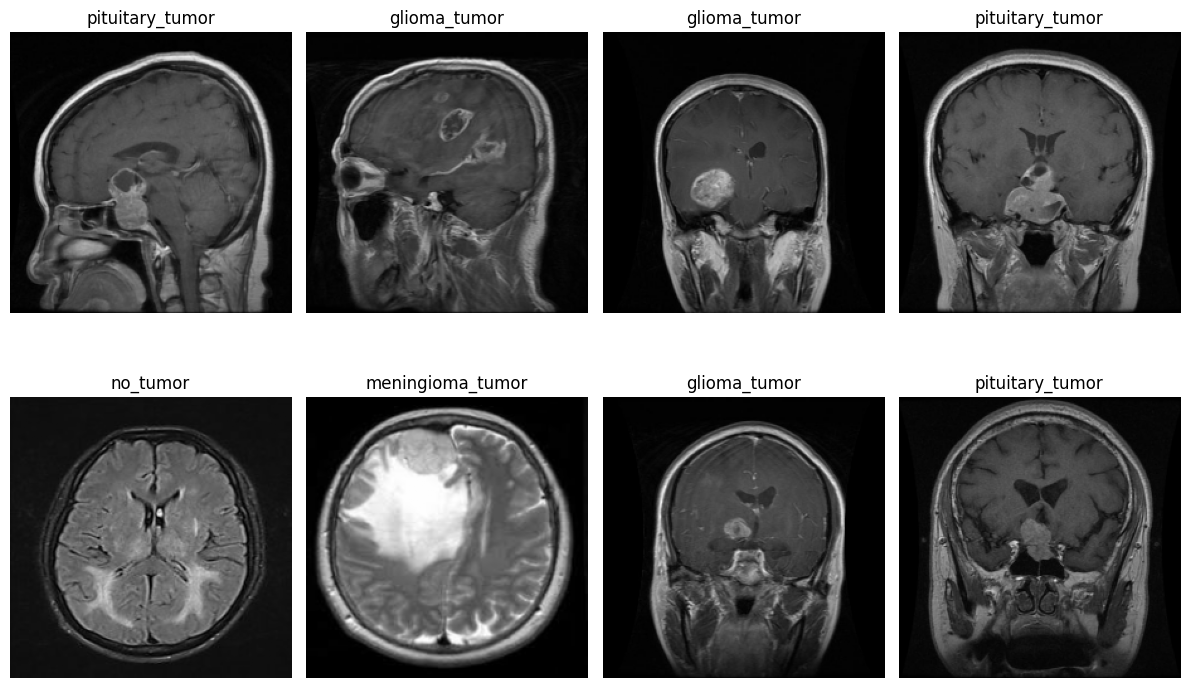

In [ ]:
import matplotlib.pyplot as plt

# Take one batch
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First labels:", labels.numpy())

# Display available images
num_images = min(8, images.shape[0])

plt.figure(figsize=(12, 8))

for i in range(num_images):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(CLASS_NAMES[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

 Define a flexible CNN architecture with configurable convolutional layers, filters, dropout, dense layers, and optimizer for Bayesian hyperparameter optimization.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models


def build_cnn(
    conv_layers,
    kernel_sizes,
    filters,
    dropout1,
    dense1,
    dropout2,
    dense2,
    optimizer_name,
    learning_rate
):

    model = models.Sequential()

    # Input layer
    model.add(layers.Input(shape=(224, 224, 3)))

    # Convolutional blocks
    for i in range(conv_layers):

        model.add(
            layers.Conv2D(
                filters=filters[i],
                kernel_size=kernel_sizes[i],
                padding="same"
            )
        )

        model.add(layers.Activation("relu"))
        model.add(layers.BatchNormalization())

        # Max pooling after every 2 convolutional layers
        if (i + 1) % 2 == 0:
            model.add(layers.MaxPooling2D(pool_size=(2, 2)))

    # Dropout
    model.add(layers.Dropout(dropout1))

    # Flatten
    model.add(layers.Flatten())

    # Dense layers
    model.add(layers.Dense(dense1, activation="relu"))
    model.add(layers.Dropout(dropout2))

    model.add(layers.Dense(dense2, activation="relu"))

    # Output layer
    model.add(layers.Dense(NUM_CLASSES, activation="softmax"))

    # Optimizer
    if optimizer_name == "Adam":

        optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    elif optimizer_name == "SGD_Nesterov":

        optimizer = tf.keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9,
            nesterov=True
        )

    else:
        raise ValueError("Unknown optimizer")

    # Compile
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
# Test configuration

test_conv_layers = 3

test_kernel_sizes = [
    (3, 3),
    (3, 3),
    (3, 3)
]

test_filters = [
    32,
    32,
    64
]

test_dropout1 = 0.3
test_dense1 = 128
test_dropout2 = 0.2
test_dense2 = 64

test_optimizer = "Adam"
test_learning_rate = 0.001

test_model = build_cnn(
    conv_layers=test_conv_layers,
    kernel_sizes=test_kernel_sizes,
    filters=test_filters,
    dropout1=test_dropout1,
    dense1=test_dense1,
    dropout2=test_dropout2,
    dense2=test_dense2,
    optimizer_name=test_optimizer,
    learning_rate=test_learning_rate
)

test_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 802816)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │   102,760,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,798,244 (392.14 MB)

 Trainable params: 102,797,988 (392.14 MB)

 Non-trainable params: 256 (1.00 KB)

In [ ]:
# 1-epoch sanity test

history = test_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=1,
    verbose=1
)

print("\nSanity test completed successfully!")

74/74 ━━━━━━━━━━━━━━━━━━━━ 49s 354ms/step - accuracy: 0.4641 - loss: 11.2238 - val_accuracy: 0.2759 - val_loss: 12.5418

Sanity test completed successfully!


Search space


In [ ]:
SEARCH_SPACE = {
    "conv_layers": [5, 7, 9, 11],

    "kernel_sizes": [
        (3, 3),
        (5, 5)
    ],

    "filters": list(range(16, 257, 16)),

    "dropout": [
        0.0,
        0.2,
        0.3,
        0.4,
        0.5,
        0.6
    ],

    "optimizer": [
        "Adam",
        "SGD_Nesterov"
    ],

    "learning_rate": [
        0.001,
        0.0001
    ]
}

print("Bayesian Optimization Search Space")
print("-----------------------------------")

for parameter, values in SEARCH_SPACE.items():
    print(parameter, ":", values)

Bayesian Optimization Search Space
-----------------------------------
conv_layers : [5, 7, 9, 11]
kernel_sizes : [(3, 3), (5, 5)]
filters : [16, 32, 48, 64, 80, 96, 112, 128, 144, 160, 176, 192, 208, 224, 240, 256]
dropout : [0.0, 0.2, 0.3, 0.4, 0.5, 0.6]
optimizer : ['Adam', 'SGD_Nesterov']
learning_rate : [0.001, 0.0001]


Generating the intial configurations for the bayesian optimization

In [ ]:
import random

random.seed(42)

def generate_random_config():
    conv_layers = random.choice(SEARCH_SPACE["conv_layers"])

    kernel_sizes = [
        random.choice(SEARCH_SPACE["kernel_sizes"])
        for _ in range(conv_layers)
    ]

    filters = [
        random.choice(SEARCH_SPACE["filters"])
        for _ in range(conv_layers)
    ]

    dropout1 = random.choice(SEARCH_SPACE["dropout"])
    dropout2 = random.choice(SEARCH_SPACE["dropout"])

    dense1 = random.choice([64, 128, 192, 208, 256])
    dense2 = random.choice([32, 48, 64, 96])

    optimizer = random.choice(SEARCH_SPACE["optimizer"])
    learning_rate = random.choice(SEARCH_SPACE["learning_rate"])

    return {
        "conv_layers": conv_layers,
        "kernel_sizes": kernel_sizes,
        "filters": filters,
        "dropout1": dropout1,
        "dense1": dense1,
        "dropout2": dropout2,
        "dense2": dense2,
        "optimizer": optimizer,
        "learning_rate": learning_rate
    }


# Generate 5 initial configurations
initial_configs = [
    generate_random_config()
    for _ in range(5)
]


# Display configurations
for i, config in enumerate(initial_configs, start=1):
    print(f"\nConfiguration {i}")
    print("-" * 40)

    for key, value in config.items():
        print(f"{key}: {value}")


Configuration 1
----------------------------------------
conv_layers: 5
kernel_sizes: [(3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]
filters: [64, 48, 224, 32, 16]
dropout1: 0.0
dense1: 128
dropout2: 0.2
dense2: 32
optimizer: Adam
learning_rate: 0.0001

Configuration 2
----------------------------------------
conv_layers: 7
kernel_sizes: [(5, 5), (5, 5), (3, 3), (3, 3), (5, 5), (5, 5), (5, 5)]
filters: [80, 112, 176, 64, 48, 208, 64]
dropout1: 0.3
dense1: 256
dropout2: 0.3
dense2: 64
optimizer: Adam
learning_rate: 0.0001

Configuration 3
----------------------------------------
conv_layers: 5
kernel_sizes: [(5, 5), (3, 3), (5, 5), (5, 5), (3, 3)]
filters: [48, 32, 128, 160, 48]
dropout1: 0.2
dense1: 208
dropout2: 0.0
dense2: 64
optimizer: SGD_Nesterov
learning_rate: 0.0001

Configuration 4
----------------------------------------
conv_layers: 7
kernel_sizes: [(5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]
filters: [96, 240, 208, 144, 128, 176, 32]
dropout1: 0.2
dense1: 192
dropout2

In [ ]:
# Validate the initial configurations before training

print("Checking initial configurations...\n")

for i, config in enumerate(initial_configs, start=1):

    assert config["conv_layers"] in SEARCH_SPACE["conv_layers"]

    assert len(config["kernel_sizes"]) == config["conv_layers"]
    assert all(
        k in SEARCH_SPACE["kernel_sizes"]
        for k in config["kernel_sizes"]
    )

    assert len(config["filters"]) == config["conv_layers"]
    assert all(
        f in SEARCH_SPACE["filters"]
        for f in config["filters"]
    )

    assert config["dropout1"] in SEARCH_SPACE["dropout"]
    assert config["dropout2"] in SEARCH_SPACE["dropout"]

    assert config["optimizer"] in SEARCH_SPACE["optimizer"]

    assert config["learning_rate"] in SEARCH_SPACE["learning_rate"]

    print(f"Configuration {i}: VALID")
    print(f"  Conv layers : {config['conv_layers']}")
    print(f"  Kernels     : {config['kernel_sizes']}")
    print(f"  Filters     : {config['filters']}")
    print(f"  Dropout     : {config['dropout1']}, {config['dropout2']}")
    print(f"  Optimizer   : {config['optimizer']}")
    print(f"  LR          : {config['learning_rate']}")
    print()

print("All initial configurations are valid!")

Checking initial configurations...

Configuration 1: VALID
  Conv layers : 5
  Kernels     : [(3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]
  Filters     : [64, 48, 224, 32, 16]
  Dropout     : 0.0, 0.2
  Optimizer   : Adam
  LR          : 0.0001

Configuration 2: VALID
  Conv layers : 7
  Kernels     : [(5, 5), (5, 5), (3, 3), (3, 3), (5, 5), (5, 5), (5, 5)]
  Filters     : [80, 112, 176, 64, 48, 208, 64]
  Dropout     : 0.3, 0.3
  Optimizer   : Adam
  LR          : 0.0001

Configuration 3: VALID
  Conv layers : 5
  Kernels     : [(5, 5), (3, 3), (5, 5), (5, 5), (3, 3)]
  Filters     : [48, 32, 128, 160, 48]
  Dropout     : 0.2, 0.0
  Optimizer   : SGD_Nesterov
  LR          : 0.0001

Configuration 4: VALID
  Conv layers : 7
  Kernels     : [(5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]
  Filters     : [96, 240, 208, 144, 128, 176, 32]
  Dropout     : 0.2, 0.0
  Optimizer   : SGD_Nesterov
  LR          : 0.001

Configuration 5: VALID
  Conv layers : 7
  Kernels     : [(5, 5), (3, 

Evalution funtion

In [ ]:
import tensorflow as tf
import gc

def evaluate_configuration(config, epochs=1):

    tf.keras.backend.clear_session()
    gc.collect()

    print("\nEvaluating configuration:")
    print(config)


    model = build_cnn(
        conv_layers=config["conv_layers"],
        kernel_sizes=config["kernel_sizes"],
        filters=config["filters"],
        dropout1=config["dropout1"],
        dense1=config["dense1"],
        dropout2=config["dropout2"],
        dense2=config["dense2"],
        optimizer_name=config["optimizer"],
        learning_rate=config["learning_rate"]
    )


    history = model.fit(
        train_ds_bo,
        validation_data=val_ds_bo,
        epochs=epochs,
        steps_per_epoch=BO_TRAIN_STEPS,
        validation_steps=BO_VAL_STEPS,
        verbose=1
    )


    validation_accuracy = history.history["val_accuracy"][-1]


    del model
    del history

    tf.keras.backend.clear_session()
    gc.collect()

    return float(validation_accuracy)

In [ ]:
# Test Configuration 1

config1_score = evaluate_configuration(
    initial_configs[0],
    epochs=1
)

print("\nConfiguration 1 validation accuracy:", config1_score)


Evaluating configuration:
{'conv_layers': 5, 'kernel_sizes': [(3, 3), (5, 5), (3, 3), (3, 3), (3, 3)], 'filters': [64, 48, 224, 32, 16], 'dropout1': 0.0, 'dense1': 128, 'dropout2': 0.2, 'dense2': 32, 'optimizer': 'Adam', 'learning_rate': 0.0001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 83s 178ms/step - accuracy: 0.6002 - loss: 1.0447 - val_accuracy: 0.1533 - val_loss: 8.7993

Configuration 1 validation accuracy: 0.15325669944286346


In [ ]:
#Evaluating the intial configurations
initial_scores = [config1_score]

for i in range(1, len(initial_configs)):

    print("\n" + "=" * 60)
    print(f"Evaluating Configuration {i + 1}")
    print("=" * 60)

    score = evaluate_configuration(
        initial_configs[i],
        epochs=1
    )

    initial_scores.append(score)

print("\n" + "=" * 60)
print("INITIAL CONFIGURATION RESULTS")
print("=" * 60)

for i, score in enumerate(initial_scores, start=1):
    print(f"Configuration {i}: Validation Accuracy = {score:.4f}")


Evaluating Configuration 2

Evaluating configuration:
{'conv_layers': 7, 'kernel_sizes': [(5, 5), (5, 5), (3, 3), (3, 3), (5, 5), (5, 5), (5, 5)], 'filters': [80, 112, 176, 64, 48, 208, 64], 'dropout1': 0.3, 'dense1': 256, 'dropout2': 0.3, 'dense2': 64, 'optimizer': 'Adam', 'learning_rate': 0.0001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 141s 341ms/step - accuracy: 0.5785 - loss: 1.1886 - val_accuracy: 0.1533 - val_loss: 6.0582

Evaluating Configuration 3

Evaluating configuration:
{'conv_layers': 5, 'kernel_sizes': [(5, 5), (3, 3), (5, 5), (5, 5), (3, 3)], 'filters': [48, 32, 128, 160, 48], 'dropout1': 0.2, 'dense1': 208, 'dropout2': 0.0, 'dense2': 64, 'optimizer': 'SGD_Nesterov', 'learning_rate': 0.0001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 90s 213ms/step - accuracy: 0.6942 - loss: 0.7668 - val_accuracy: 0.3602 - val_loss: 1.4952

Evaluating Configuration 4

Evaluating configuration:
{'conv_layers': 7, 'kernel_sizes': [(5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (3, 3), (3, 3)], 'filters': [96, 240, 208, 

In [ ]:
# Store the initial configurations and their validation scores
import pandas as pd

bo_results = []

for config, score in zip(initial_configs, initial_scores):
    result = config.copy()
    result["validation_accuracy"] = score
    bo_results.append(result)

bo_results_df = pd.DataFrame(bo_results)

print("Initial Bayesian Optimization results:")
display(bo_results_df)

Initial Bayesian Optimization results:


,conv_layers,kernel_sizes,filters,dropout1,dense1,dropout2,dense2,optimizer,learning_rate,validation_accuracy
0,5,"[(3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]","[64, 48, 224, 32, 16]",0.0,128,0.2,32,Adam,0.0001,0.153257
1,7,"[(5, 5), (5, 5), (3, 3), (3, 3), (5, 5), (5, 5...","[80, 112, 176, 64, 48, 208, 64]",0.3,256,0.3,64,Adam,0.0001,0.153257
2,5,"[(5, 5), (3, 3), (5, 5), (5, 5), (3, 3)]","[48, 32, 128, 160, 48]",0.2,208,0.0,64,SGD_Nesterov,0.0001,0.360153
3,7,"[(5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (3, 3...","[96, 240, 208, 144, 128, 176, 32]",0.2,192,0.0,96,SGD_Nesterov,0.0010,0.655172
4,7,"[(5, 5), (3, 3), (5, 5), (5, 5), (5, 5), (3, 3...","[80, 128, 144, 224, 208, 192, 128]",0.2,208,0.5,32,Adam,0.0010,0.371648


In [ ]:
import numpy as np

def encode_configuration(config):

    features = []

    features.append(config["conv_layers"])

    for kernel in config["kernel_sizes"]:
        features.append(kernel[0])

    while len(features) < 1 + 11:
        features.append(0)

    for f in config["filters"]:
        features.append(f)

    current_filter_count = len(config["filters"])
    for _ in range(11 - current_filter_count):
        features.append(0)

    features.append(config["dropout1"])
    features.append(config["dropout2"])

    features.append(config["dense1"])
    features.append(config["dense2"])

    if config["optimizer"] == "Adam":
        features.append(0)
    else:
        features.append(1)

    features.append(config["learning_rate"])

    return np.array(features, dtype=np.float64)

X_initial = np.array([
    encode_configuration(config)
    for config in initial_configs
])

y_initial = np.array(initial_scores)

print("Encoded configuration shape:", X_initial.shape)
print("Validation score shape:", y_initial.shape)

print("\nFirst encoded configuration:")
print(X_initial[0])

print("\nValidation scores:")
print(y_initial)

Encoded configuration shape: (5, 29)
Validation score shape: (5,)

First encoded configuration:
[5.00e+00 3.00e+00 5.00e+00 3.00e+00 3.00e+00 3.00e+00 0.00e+00 0.00e+00
 0.00e+00 0.00e+00 0.00e+00 0.00e+00 6.40e+01 4.80e+01 2.24e+02 3.20e+01
 1.60e+01 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00
 2.00e-01 1.28e+02 3.20e+01 0.00e+00 1.00e-04]

Validation scores:
[0.1532567  0.1532567  0.36015326 0.65517241 0.37164751]


Gaussian Process

In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_initial)

# Gaussian Process kernel
kernel = ConstantKernel(1.0) * Matern(
    length_scale=1.0,
    nu=2.5
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-6,
    normalize_y=True,
    random_state=42,
    n_restarts_optimizer=5
)

gp.fit(X_scaled, y_initial)

print("Gaussian Process fitted successfully!")

print("\nTraining points:", X_scaled.shape[0])
print("Features per configuration:", X_scaled.shape[1])

print("\nLearned kernel:")
print(gp.kernel_)

Gaussian Process fitted successfully!

Training points: 5
Features per configuration: 29

Learned kernel:
1**2 * Matern(length_scale=1e-05, nu=2.5)


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Expected improvment

In [ ]:
from scipy.stats import norm
import numpy as np

def expected_improvement(X_candidates, gp, best_score, xi=0.01):


    X_candidates_scaled = scaler.transform(X_candidates)

    mean, std = gp.predict(
        X_candidates_scaled,
        return_std=True
    )


    std = np.maximum(std, 1e-9)

    improvement = mean - best_score - xi

    z = improvement / std

    ei = improvement * norm.cdf(z) + std * norm.pdf(z)

    return ei, mean, std


print("Expected Improvement function created successfully!")

Expected Improvement function created successfully!


In [ ]:
NUM_CANDIDATES = 100

candidate_configs = [
    generate_random_config()
    for _ in range(NUM_CANDIDATES)
]

evaluated_config_keys = {
    str(config) for config in initial_configs
}

candidate_configs = [
    config for config in candidate_configs
    if str(config) not in evaluated_config_keys
]

X_candidates = np.array([
    encode_configuration(config)
    for config in candidate_configs
])

best_score = max(initial_scores)

ei_values, predicted_mean, predicted_std = expected_improvement(
    X_candidates,
    gp,
    best_score
)

best_candidate_index = np.argmax(ei_values)

next_config = candidate_configs[best_candidate_index]

print("Current best validation accuracy:", best_score)

print("\nSelected next configuration:")
print("-" * 45)

for key, value in next_config.items():
    print(f"{key}: {value}")

print("\nPredicted mean:", predicted_mean[best_candidate_index])
print("Predicted standard deviation:", predicted_std[best_candidate_index])
print("Expected Improvement:", ei_values[best_candidate_index])

Current best validation accuracy: 0.6551724076271057

Selected next configuration:
---------------------------------------------
conv_layers: 9
kernel_sizes: [(3, 3), (3, 3), (5, 5), (5, 5), (3, 3), (3, 3), (5, 5), (5, 5), (3, 3)]
filters: [32, 128, 48, 48, 256, 48, 80, 80, 256]
dropout1: 0.5
dense1: 192
dropout2: 0.2
dense2: 96
optimizer: Adam
learning_rate: 0.001

Predicted mean: 0.33869731426239014
Predicted standard deviation: 0.18465039366472358
Expected Improvement: 0.002855398012366981


In [ ]:
# Evaluate the configuration selected by Expected Improvement

config6_score = evaluate_configuration(
    next_config,
    epochs=1
)

print("\nConfiguration 6 validation accuracy:", config6_score)


Evaluating configuration:
{'conv_layers': 9, 'kernel_sizes': [(3, 3), (3, 3), (5, 5), (5, 5), (3, 3), (3, 3), (5, 5), (5, 5), (3, 3)], 'filters': [32, 128, 48, 48, 256, 48, 80, 80, 256], 'dropout1': 0.5, 'dense1': 192, 'dropout2': 0.2, 'dense2': 96, 'optimizer': 'Adam', 'learning_rate': 0.001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 91s 206ms/step - accuracy: 0.4028 - loss: 2.7521 - val_accuracy: 0.1379 - val_loss: 11.6543

Configuration 6 validation accuracy: 0.13793103396892548


In [ ]:
# Add Configuration 6 to the BO history

bo_results.append({
    **next_config,
    "validation_accuracy": config6_score
})

# Update the configuration and score arrays
all_configs = [
    {key: value for key, value in result.items()
     if key != "validation_accuracy"}
    for result in bo_results
]

all_scores = np.array([
    result["validation_accuracy"]
    for result in bo_results
])

X_all = np.array([
    encode_configuration(config)
    for config in all_configs
])


X_all_scaled = scaler.fit_transform(X_all)

gp.fit(X_all_scaled, all_scores)

print("Gaussian Process updated successfully!")

print("\nTotal evaluated configurations:", len(all_configs))

print("\nValidation accuracies:")
for i, score in enumerate(all_scores, start=1):
    print(f"Configuration {i}: {score:.4f}")

print("\nCurrent best validation accuracy:", max(all_scores))
print("Best configuration number:", np.argmax(all_scores) + 1)

Gaussian Process updated successfully!

Total evaluated configurations: 6

Validation accuracies:
Configuration 1: 0.1533
Configuration 2: 0.1533
Configuration 3: 0.3602
Configuration 4: 0.6552
Configuration 5: 0.3716
Configuration 6: 0.1379

Current best validation accuracy: 0.6551724076271057
Best configuration number: 4


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [ ]:
# Select the next configuration using Expected Improvement

NUM_CANDIDATES = 100

candidate_configs = [
    generate_random_config()
    for _ in range(NUM_CANDIDATES)
]

evaluated_config_keys = {
    str(config) for config in all_configs
}

candidate_configs = [
    config for config in candidate_configs
    if str(config) not in evaluated_config_keys
]


X_candidates = np.array([
    encode_configuration(config)
    for config in candidate_configs
])

best_score = max(all_scores)

ei_values, predicted_mean, predicted_std = expected_improvement(
    X_candidates,
    gp,
    best_score
)


best_candidate_index = np.argmax(ei_values)

next_config = candidate_configs[best_candidate_index]

print("Current best validation accuracy:", best_score)

print("\nSelected Configuration 7:")
print("-" * 45)

for key, value in next_config.items():
    print(f"{key}: {value}")

print("\nPredicted mean:",
      predicted_mean[best_candidate_index])

print("Predicted standard deviation:",
      predicted_std[best_candidate_index])

print("Expected Improvement:",
      ei_values[best_candidate_index])

Current best validation accuracy: 0.6551724076271057

Selected Configuration 7:
---------------------------------------------
conv_layers: 9
kernel_sizes: [(3, 3), (3, 3), (5, 5), (5, 5), (5, 5), (3, 3), (3, 3), (3, 3), (5, 5)]
filters: [128, 128, 240, 192, 208, 240, 80, 192, 16]
dropout1: 0.4
dense1: 192
dropout2: 0.0
dense2: 96
optimizer: Adam
learning_rate: 0.001

Predicted mean: 0.3052362675468127
Predicted standard deviation: 0.18442164150686124
Expected Improvement: 0.0017805020485249321


In [ ]:
# Evaluate Configuration 7 selected by Expected Improvement

config7_score = evaluate_configuration(
    next_config,
    epochs=1
)

print("\nConfiguration 7 validation accuracy:", config7_score)


Evaluating configuration:
{'conv_layers': 9, 'kernel_sizes': [(3, 3), (3, 3), (5, 5), (5, 5), (5, 5), (3, 3), (3, 3), (3, 3), (5, 5)], 'filters': [128, 128, 240, 192, 208, 240, 80, 192, 16], 'dropout1': 0.4, 'dense1': 192, 'dropout2': 0.0, 'dense2': 96, 'optimizer': 'Adam', 'learning_rate': 0.001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 251s 637ms/step - accuracy: 0.5823 - loss: 1.0344 - val_accuracy: 0.2950 - val_loss: 1.4816

Configuration 7 validation accuracy: 0.29501914978027344


In [ ]:

# AUTOMATIC BAYESIAN OPTIMIZATION LOOP


TOTAL_CONFIGURATIONS = 20
NUM_CANDIDATES = 100
BO_EPOCHS = 1

print("=" * 70)
print("AUTOMATIC BAYESIAN OPTIMIZATION")
print("=" * 70)

while len(all_configs) < TOTAL_CONFIGURATIONS:

    current_number = len(all_configs) + 1

    print("\n" + "=" * 70)
    print(f"BO ITERATION → Configuration {current_number}")
    print("=" * 70)

    candidate_configs = [
        generate_random_config()
        for _ in range(NUM_CANDIDATES)
    ]

    evaluated_keys = {
        str(config)
        for config in all_configs
    }

    candidate_configs = [
        config
        for config in candidate_configs
        if str(config) not in evaluated_keys
    ]

    X_candidates = np.array([
        encode_configuration(config)
        for config in candidate_configs
    ])

    best_score = max(all_scores)


    ei_values, predicted_mean, predicted_std = (
        expected_improvement(
            X_candidates,
            gp,
            best_score
        )
    )


    best_candidate_index = np.argmax(ei_values)

    selected_config = candidate_configs[
        best_candidate_index
    ]

    print("\nSelected configuration:")
    print(selected_config)

    print(
        "\nPredicted mean:",
        predicted_mean[best_candidate_index]
    )

    print(
        "Predicted uncertainty:",
        predicted_std[best_candidate_index]
    )

    print(
        "Expected Improvement:",
        ei_values[best_candidate_index]
    )

    selected_score = evaluate_configuration(
        selected_config,
        epochs=BO_EPOCHS
    )

    print(
        f"\nActual validation accuracy: "
        f"{selected_score:.4f}"
    )


    bo_results.append({
        **selected_config,
        "validation_accuracy": selected_score
    })


    all_configs = [
        {
            key: value
            for key, value in result.items()
            if key != "validation_accuracy"
        }
        for result in bo_results
    ]

    all_scores = np.array([
        result["validation_accuracy"]
        for result in bo_results
    ])


    X_all = np.array([
        encode_configuration(config)
        for config in all_configs
    ])

    X_all_scaled = scaler.fit_transform(X_all)

    gp.fit(
        X_all_scaled,
        all_scores
    )


    best_index = np.argmax(all_scores)

    print("\nCurrent BO best:")
    print(
        f"Configuration {best_index + 1}"
    )
    print(
        f"Validation accuracy: "
        f"{all_scores[best_index]:.4f}"
    )

    print(
        f"\nConfigurations evaluated: "
        f"{len(all_configs)}/{TOTAL_CONFIGURATIONS}"
    )


best_index = np.argmax(all_scores)

best_config = all_configs[best_index]
best_validation_accuracy = all_scores[best_index]

print("\n" + "=" * 70)
print("BAYESIAN OPTIMIZATION FINISHED")
print("=" * 70)

print(
    f"\nTotal configurations evaluated: "
    f"{len(all_configs)}"
)

print(
    f"Best configuration: "
    f"Configuration {best_index + 1}"
)

print(
    f"Best validation accuracy: "
    f"{best_validation_accuracy:.4f}"
)

print("\nBest configuration parameters:")

for key, value in best_config.items():
    print(f"{key}: {value}")

AUTOMATIC BAYESIAN OPTIMIZATION

BO ITERATION → Configuration 7

Selected configuration:
{'conv_layers': 7, 'kernel_sizes': [(5, 5), (5, 5), (3, 3), (5, 5), (5, 5), (5, 5), (5, 5)], 'filters': [192, 224, 224, 176, 128, 112, 208], 'dropout1': 0.5, 'dense1': 192, 'dropout2': 0.6, 'dense2': 64, 'optimizer': 'SGD_Nesterov', 'learning_rate': 0.0001}

Predicted mean: 0.3052362675468127
Predicted uncertainty: 0.18442164150686124
Expected Improvement: 0.0017805020485249321

Evaluating configuration:
{'conv_layers': 7, 'kernel_sizes': [(5, 5), (5, 5), (3, 3), (5, 5), (5, 5), (5, 5), (5, 5)], 'filters': [192, 224, 224, 176, 128, 112, 208], 'dropout1': 0.5, 'dense1': 192, 'dropout2': 0.6, 'dense2': 64, 'optimizer': 'SGD_Nesterov', 'learning_rate': 0.0001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 437s 1s/step - accuracy: 0.4751 - loss: 1.4608 - val_accuracy: 0.2835 - val_loss: 3.2035

Actual validation accuracy: 0.2835

Current BO best:
Configuration 4
Validation accuracy: 0.6552

Configurations evaluated: 7/

/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(



Evaluating configuration:
{'conv_layers': 7, 'kernel_sizes': [(3, 3), (5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (3, 3)], 'filters': [224, 224, 256, 160, 32, 256, 208], 'dropout1': 0.4, 'dense1': 256, 'dropout2': 0.5, 'dense2': 96, 'optimizer': 'Adam', 'learning_rate': 0.001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 507s 1s/step - accuracy: 0.3254 - loss: 14.4271 - val_accuracy: 0.1533 - val_loss: 235.4989

Actual validation accuracy: 0.1533

Current BO best:
Configuration 4
Validation accuracy: 0.6552

Configurations evaluated: 8/20

BO ITERATION → Configuration 9

Selected configuration:
{'conv_layers': 9, 'kernel_sizes': [(3, 3), (5, 5), (3, 3), (5, 5), (3, 3), (5, 5), (3, 3), (3, 3), (5, 5)], 'filters': [32, 128, 208, 96, 48, 240, 256, 176, 208], 'dropout1': 0.4, 'dense1': 64, 'dropout2': 0.2, 'dense2': 64, 'optimizer': 'SGD_Nesterov', 'learning_rate': 0.001}

Predicted mean: 0.28352490067481995
Predicted uncertainty: 0.16728200864754345
Expected Improvement: 0.0006465998402606287

Evaluating co

/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(



Evaluating configuration:
{'conv_layers': 9, 'kernel_sizes': [(5, 5), (3, 3), (3, 3), (5, 5), (5, 5), (3, 3), (3, 3), (3, 3), (5, 5)], 'filters': [144, 112, 240, 224, 32, 240, 160, 32, 64], 'dropout1': 0.4, 'dense1': 192, 'dropout2': 0.4, 'dense2': 32, 'optimizer': 'SGD_Nesterov', 'learning_rate': 0.0001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 224s 570ms/step - accuracy: 0.5006 - loss: 1.2927 - val_accuracy: 0.2835 - val_loss: 2.1793

Actual validation accuracy: 0.2835


...


Evaluating configuration:
{'conv_layers': 7, 'kernel_sizes': [(3, 3), (5, 5), (3, 3), (3, 3), (3, 3), (5, 5), (5, 5)], 'filters': [256, 224, 64, 256, 64, 224, 96], 'dropout1': 0.0, 'dense1': 128, 'dropout2': 0.3, 'dense2': 64, 'optimizer': 'Adam', 'learning_rate': 0.0001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 451s 1s/step - accuracy: 0.5555 - loss: 1.2299 - val_accuracy: 0.2874 - val_loss: 5.2530

Actual validation accuracy: 0.2874

Current BO best:
Configuration 4
Validation accuracy: 0.6552

Configurations evaluated: 14/20

BO ITERATION → Configuration 15

Selected configuration:
{'conv_layers': 9, 'kernel_sizes': [(3, 3), (3, 3), (5, 5), (3, 3), (5, 5), (5, 5), (5, 5), (3, 3), (3, 3)], 'filters': [16, 256, 48, 240, 64, 32, 208, 176, 224], 'dropout1': 0.3, 'dense1': 192, 'dropout2': 0.2, 'dense2': 96, 'optimizer': 'Adam', 'learning_rate': 0.0001}

Predicted mean: 0.2895457015505859
Predicted uncertainty: 0.14938109700925323
Expected Improvement: 0.00028615456720015517


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(



Evaluating configuration:
{'conv_layers': 9, 'kernel_sizes': [(3, 3), (3, 3), (5, 5), (3, 3), (5, 5), (5, 5), (5, 5), (3, 3), (3, 3)], 'filters': [16, 256, 48, 240, 64, 32, 208, 176, 224], 'dropout1': 0.3, 'dense1': 192, 'dropout2': 0.2, 'dense2': 96, 'optimizer': 'Adam', 'learning_rate': 0.0001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 125s 297ms/step - accuracy: 0.5972 - loss: 1.0386 - val_accuracy: 0.3755 - val_loss: 1.5246

Actual validation accuracy: 0.3755


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(



Current BO best:
Configuration 4
Validation accuracy: 0.6552

Configurations evaluated: 15/20

BO ITERATION → Configuration 16

Selected configuration:
{'conv_layers': 7, 'kernel_sizes': [(3, 3), (5, 5), (3, 3), (3, 3), (5, 5), (5, 5), (5, 5)], 'filters': [224, 192, 64, 64, 16, 224, 48], 'dropout1': 0.4, 'dense1': 192, 'dropout2': 0.2, 'dense2': 96, 'optimizer': 'Adam', 'learning_rate': 0.001}

Predicted mean: 0.2952745830019315
Predicted uncertainty: 0.14589909378001295
Expected Improvement: 0.0002619687147207956

Evaluating configuration:
{'conv_layers': 7, 'kernel_sizes': [(3, 3), (5, 5), (3, 3), (3, 3), (5, 5), (5, 5), (5, 5)], 'filters': [224, 192, 64, 64, 16, 224, 48], 'dropout1': 0.4, 'dense1': 192, 'dropout2': 0.2, 'dense2': 96, 'optimizer': 'Adam', 'learning_rate': 0.001}
294/294 ━━━━━━━━━━━━━━━━━━━━ 357s 931ms/step - accuracy: 0.4500 - loss: 2.1500 - val_accuracy: 0.2414 - val_loss: 7.4429

Actual validation accuracy: 0.2414

Current BO best:
Configuration 4
Validation accur

In [ ]:
import json
import os

# ============================================================
# RECOVER AND SAVE BEST BO CONFIGURATION
# From completed BO run: Configuration 4
# ============================================================

best_config = {
    "conv_layers": 7,
    "kernel_sizes": [
        (5,5),
        (5,5),
        (3,3),
        (5,5),
        (3,3),
        (3,3),
        (3,3)
    ],
    "filters": [96, 240, 208, 144, 128, 176, 32],
    "dropout1": 0.2,
    "dense1": 192,
    "dropout2": 0.0,
    "dense2": 96,
    "optimizer": "SGD_Nesterov",
    "learning_rate": 0.001
}

best_validation_accuracy = 0.6552

# Save location
save_dir = "/content/drive/MyDrive/BrainTumor_BO_Reproduction"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(
    save_dir,
    "dataset1_best_config.json"
)

# Convert tuples to lists for JSON
config_to_save = best_config.copy()
config_to_save["kernel_sizes"] = [
    list(k) for k in config_to_save["kernel_sizes"]
]

config_to_save["validation_accuracy"] = best_validation_accuracy
config_to_save["configuration_number"] = 4

with open(save_path, "w") as f:
    json.dump(config_to_save, f, indent=4)

print("=" * 60)
print("BEST CONFIGURATION SAVED")
print("=" * 60)

print("\nConfiguration: 4")
print("Validation Accuracy:", best_validation_accuracy)

print("\nSaved to:")
print(save_path)

print("\nConfiguration:")
for key, value in config_to_save.items():
    print(f"{key}: {value}")

BEST CONFIGURATION SAVED

Configuration: 4
Validation Accuracy: 0.6552

Saved to:
/content/drive/MyDrive/BrainTumor_BO_Reproduction/dataset1_best_config.json

Configuration:
conv_layers: 7
kernel_sizes: [[5, 5], [5, 5], [3, 3], [5, 5], [3, 3], [3, 3], [3, 3]]
filters: [96, 240, 208, 144, 128, 176, 32]
dropout1: 0.2
dense1: 192
dropout2: 0.0
dense2: 96
optimizer: SGD_Nesterov
learning_rate: 0.001
validation_accuracy: 0.6552
configuration_number: 4


In [ ]:
# Best configuration selected by the completed BO search
# Configuration 4

best_config = {
    "conv_layers": 7,
    "kernel_sizes": [
        (5, 5),
        (5, 5),
        (3, 3),
        (5, 5),
        (3, 3),
        (3, 3),
        (3, 3)
    ],
    "filters": [96, 240, 208, 144, 128, 176, 32],
    "dropout1": 0.2,
    "dense1": 192,
    "dropout2": 0.0,
    "dense2": 96,
    "optimizer": "SGD_Nesterov",
    "learning_rate": 0.001
}

print("Best Configuration 4 loaded")
print("Validation accuracy during BO: 65.52%")
print("\nConfiguration:")
for key, value in best_config.items():
    print(f"{key}: {value}")

Best Configuration 4 loaded
Validation accuracy during BO: 65.52%

Configuration:
conv_layers: 7
kernel_sizes: [(5, 5), (5, 5), (3, 3), (5, 5), (3, 3), (3, 3), (3, 3)]
filters: [96, 240, 208, 144, 128, 176, 32]
dropout1: 0.2
dense1: 192
dropout2: 0.0
dense2: 96
optimizer: SGD_Nesterov
learning_rate: 0.001


In [ ]:
# Final training of the best BO configuration

EPOCHS = 50
print("Starting final training...")
print(f"Epochs: {EPOCHS}")
print(f"Batch size: 8")
print(f"Training steps per epoch: {BO_TRAIN_STEPS}")
print(f"Validation steps: {BO_VAL_STEPS}")

history = final_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    steps_per_epoch=BO_TRAIN_STEPS,
    validation_steps=BO_VAL_STEPS,
    verbose=1
)

print("\nFinal training completed!")

Starting final training...
Epochs: 50
Batch size: 8
Training steps per epoch: 294
Validation steps: 33
Epoch 1/50
294/294 ━━━━━━━━━━━━━━━━━━━━ 281s 751ms/step - accuracy: 0.6601 - loss: 0.8455 - val_accuracy: 0.4943 - val_loss: 1.3150
Epoch 2/50
294/294 ━━━━━━━━━━━━━━━━━━━━ 158s 536ms/step - accuracy: 0.8303 - loss: 0.4371 - val_accuracy: 0.8161 - val_loss: 0.4993
Epoch 3/50
294/294 ━━━━━━━━━━━━━━━━━━━━ 157s 535ms/step - accuracy: 0.8962 - loss: 0.2570 - val_accuracy: 0.8506 - val_loss: 0.4160
Epoch 4/50
294/294 ━━━━━━━━━━━━━━━━━━━━ 158s 536ms/step - accuracy: 0.9481 - loss: 0.1452 - val_accuracy: 0.8621 - val_loss: 0.3668
Epoch 5/50
294/294 ━━━━━━━━━━━━━━━━━━━━ 158s 538ms/step - accuracy: 0.9741 - loss: 0.0781 - val_accuracy: 0.8697 - val_loss: 0.4435
Epoch 6/50
294/294 ━━━━━━━━━━━━━━━━━━━━ 158s 537ms/step - accuracy: 0.9838 - loss: 0.0537 - val_accuracy: 0.8851 - val_loss: 0.3370
Epoch 7/50
294/294 ━━━━━━━━━━━━━━━━━━━━ 158s 538ms/step - accuracy: 0.9906 - loss: 0.0281 - val_accuracy:

In [ ]:
# Final evaluation on Dataset 1 test set

print("Evaluating final model on the test set...\n")

test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    steps=BO_TEST_STEPS,
    verbose=1
)

print("\n" + "="*50)
print("FINAL TEST RESULTS")
print("="*50)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy*100:.2f}%")

Evaluating final model on the test set...

82/82 ━━━━━━━━━━━━━━━━━━━━ 17s 202ms/step - accuracy: 0.9110 - loss: 0.4890

FINAL TEST RESULTS
Test Loss     : 0.4890
Test Accuracy : 0.9110
Test Accuracy : 91.10%


In [ ]:
# Generate predictions for the complete test set

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

print("Generating predictions...")

y_true = []
y_pred = []

for images, labels in test_ds.take(BO_TEST_STEPS):
    predictions = final_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated!")
print("Number of true labels :", len(y_true))
print("Number of predictions :", len(y_pred))

Generating predictions...
Predictions generated!
Number of true labels : 652
Number of predictions : 652


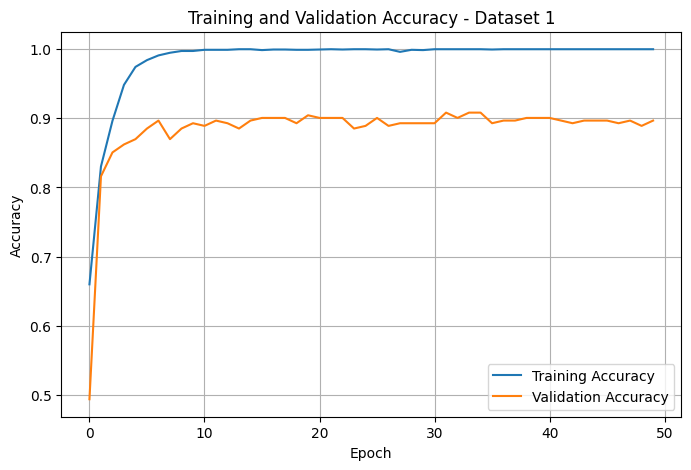

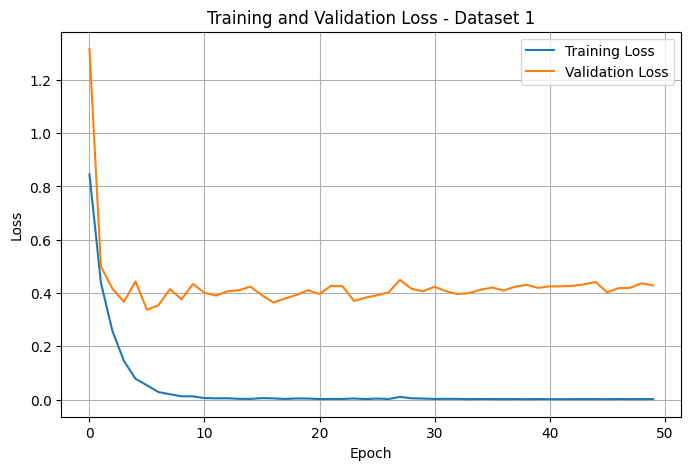

In [ ]:
import matplotlib.pyplot as plt

# Training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - Dataset 1")
plt.legend()
plt.grid(True)
plt.show()


# Training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss - Dataset 1")
plt.legend()
plt.grid(True)
plt.show()

CONFUSION MATRIX
[[160  16   1   8]
 [ 12 166   1   8]
 [  1   4 175   0]
 [  3   1   3  93]]

CLASSIFICATION REPORT
                  precision    recall  f1-score   support

    glioma_tumor     0.9091    0.8649    0.8864       185
meningioma_tumor     0.8877    0.8877    0.8877       187
 pituitary_tumor     0.9722    0.9722    0.9722       180
        no_tumor     0.8532    0.9300    0.8900       100

        accuracy                         0.9110       652
       macro avg     0.9056    0.9137    0.9091       652
    weighted avg     0.9118    0.9110    0.9110       652



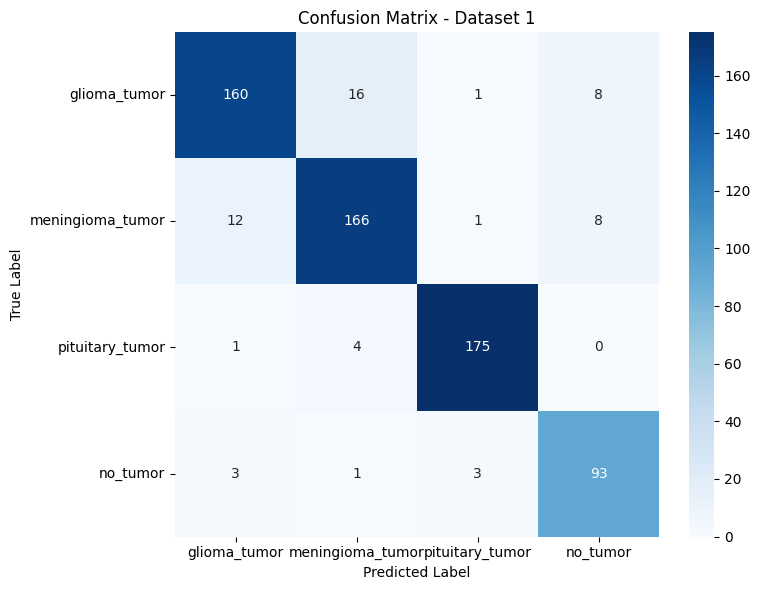

In [ ]:
# Confusion Matrix and Classification Report

cm = confusion_matrix(y_true, y_pred)

print("CONFUSION MATRIX")
print(cm)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Dataset 1")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import matthews_corrcoef, cohen_kappa_score

# Calculate MCC
mcc = matthews_corrcoef(y_true, y_pred)

# Calculate Cohen's Kappa
kappa = cohen_kappa_score(y_true, y_pred)

print("=" * 50)
print("ADDITIONAL EVALUATION METRICS")
print("=" * 50)

print(f"MCC (Matthews Correlation Coefficient): {mcc:.4f}")
print(f"Cohen's Kappa:                         {kappa:.4f}")

ADDITIONAL EVALUATION METRICS
MCC (Matthews Correlation Coefficient): 0.8799
Cohen's Kappa:                         0.8797


In [ ]:
import os
import json
import numpy as np
from sklearn.metrics import classification_report

RESULTS_DIR = "/content/drive/MyDrive/BrainTumor_BO_Reproduction/dataset1_final_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

model_path = os.path.join(RESULTS_DIR, "dataset1_final_model.keras")
final_model.save(model_path)


report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    output_dict=True
)


results = {
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_accuracy_percent": float(test_accuracy * 100),
    "mcc": float(mcc),
    "cohen_kappa": float(kappa),
    "confusion_matrix": cm.tolist(),
    "classification_report": report,
    "best_configuration": best_config,
    "bo_validation_accuracy": 0.6552,
    "bo_configuration_number": 4,
    "epochs": 50,
    "batch_size": 8,
    "test_samples": 652
}

results_path = os.path.join(RESULTS_DIR, "dataset1_final_results.json")

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

cm_path = os.path.join(RESULTS_DIR, "dataset1_confusion_matrix.npy")
np.save(cm_path, cm)

print(" Dataset 1 final results saved successfully!")
print("\nSaved files:")
print("1.", model_path)
print("2.", results_path)
print("3.", cm_path)

 Dataset 1 final results saved successfully!

Saved files:
1. /content/drive/MyDrive/BrainTumor_BO_Reproduction/dataset1_final_results/dataset1_final_model.keras
2. /content/drive/MyDrive/BrainTumor_BO_Reproduction/dataset1_final_results/dataset1_final_results.json
3. /content/drive/MyDrive/BrainTumor_BO_Reproduction/dataset1_final_results/dataset1_confusion_matrix.npy
